<a href="https://colab.research.google.com/github/ShimaArasteh/admet-pytorch/blob/main/01_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
what_were_covering = {1:"data (prepare and load)",
                      2: "build model",
                      3: "fitting the model to data(training)",
                      4: "making predictions and evaluating a model (inference)",
                      5: "saving and loading a model",
                      6: "putting it all together"
                      }

In [5]:
import torch

In [6]:
from torch import nn
import matplotlib.pyplot as plt
torch.__version__

'2.14.1+cpu'

In [7]:
weight = 0.7
bias = 0.3

In [8]:
# create data
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

In [9]:
X

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])

In [10]:
train_split = int(0.8 * len(X))

In [11]:
X_train, y_train = X[:train_split], y[:train_split]

In [12]:
X_test, y_test = X[train_split:], y[train_split:]

In [13]:
def plot_predictions(train_data = X_train,
                     train_labels = y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None
                     ):
plt.figure(figsize=(10, 7))
plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
plt.scatter(test_data, test_labels. c="c", s=4, label="Testing_data")
if predictions is not None:
   plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")
   plt.legend(prop={"size": 14})

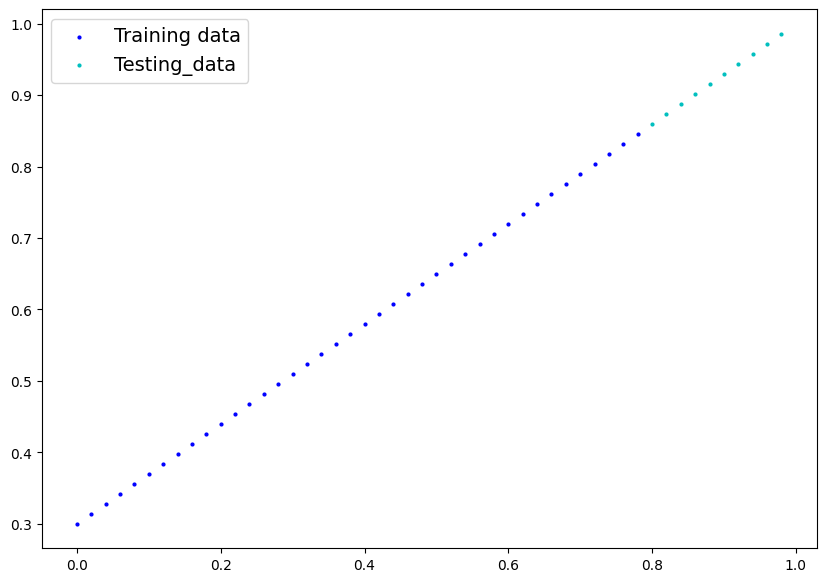

In [14]:
plot_predictions()

In [15]:
#Create a linear regression model class

In [37]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float))
    self.bias = nn.Parameter(torch.randn(1,
                                         requires_grad=True, dtype=torch.float))
  def forward(self, x:torch.Tensor) -> torch.Tensor:
      return self.weights * x + self.bias

In [38]:
torch.manual_seed(42)

In [39]:
model_0 = LinearRegressionModel()

In [40]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [41]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [42]:
with torch.inference_mode():
  y_preds = model_0(X_test)

In [46]:
print(f"number of predictions made: {len(y_preds)}")

number of predictions made: 10


In [44]:
print(f"number of testing samples: {len(X_test)}")

number of testing samples: 10


In [45]:
print (f"Predicted values: :\n{y_preds}")

Predicted values: :
tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])


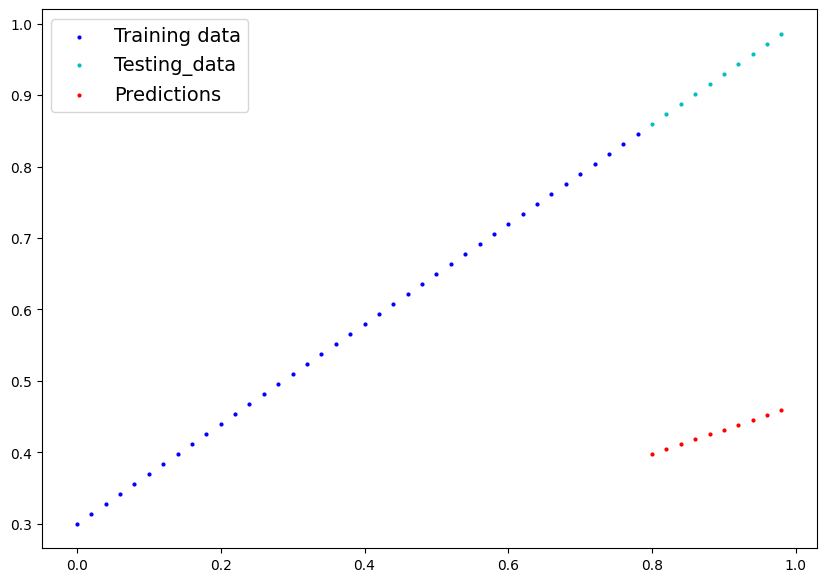

In [47]:
plot_predictions(predictions=y_preds)

In [51]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.01)

In [54]:
parameters = model_0.parameters()